In [21]:
# Importation des packages

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration esthétique pour les graphiques 
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("colorblind")

In [22]:
# Chargement des données
df = pd.read_csv("C:/Users/TESLA ELECTRONICS/Desktop/DATA_SCIENCE/fraud_oracle.csv")

# Aperçu global
print("=== DIMENSIONS DU DATASET ===")
print(f"Lignes (Sinistres) : {df.shape[0]}")
print(f"Colonnes (Variables) : {df.shape[1]}\n")

print("=== TYPES DE VARIABLES ===")
print(df.dtypes.value_counts(), "\n")

# Affichage des 3 premières lignes pour visualiser le format brut
display(df.head(3)) 

=== DIMENSIONS DU DATASET ===
Lignes (Sinistres) : 15420
Colonnes (Variables) : 33

=== TYPES DE VARIABLES ===
object    24
int64      9
Name: count, dtype: int64 



,Month,WeekOfMonth,DayOfWeek,Make,AccidentArea,DayOfWeekClaimed,MonthClaimed,WeekOfMonthClaimed,Sex,MaritalStatus,...,AgeOfVehicle,AgeOfPolicyHolder,PoliceReportFiled,WitnessPresent,AgentType,NumberOfSuppliments,AddressChange_Claim,NumberOfCars,Year,BasePolicy
0,Dec,5,Wednesday,Honda,Urban,Tuesday,Jan,1,Female,Single,...,3 years,26 to 30,No,No,External,none,1 year,3 to 4,1994,Liability
1,Jan,3,Wednesday,Honda,Urban,Monday,Jan,4,Male,Single,...,6 years,31 to 35,Yes,No,External,none,no change,1 vehicle,1994,Collision
2,Oct,5,Friday,Honda,Urban,Thursday,Nov,2,Male,Married,...,7 years,41 to 50,No,No,External,none,no change,1 vehicle,1994,Collision


In [23]:
df.info() 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15420 entries, 0 to 15419
Data columns (total 33 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Month                 15420 non-null  object
 1   WeekOfMonth           15420 non-null  int64 
 2   DayOfWeek             15420 non-null  object
 3   Make                  15420 non-null  object
 4   AccidentArea          15420 non-null  object
 5   DayOfWeekClaimed      15420 non-null  object
 6   MonthClaimed          15420 non-null  object
 7   WeekOfMonthClaimed    15420 non-null  int64 
 8   Sex                   15420 non-null  object
 9   MaritalStatus         15420 non-null  object
 10  Age                   15420 non-null  int64 
 11  Fault                 15420 non-null  object
 12  PolicyType            15420 non-null  object
 13  VehicleCategory       15420 non-null  object
 14  VehiclePrice          15420 non-null  object
 15  FraudFound_P          15420 non-null

In [24]:
# Analyse de la variable cible (FraudFound_P)
print("=== DISTRIBUTION DE LA VARIABLE CIBLE ===")
target_counts = df['FraudFound_P'].value_counts(dropna=False)
target_pct = df['FraudFound_P'].value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    'Nombre de sinistres': target_counts,
    'Proportion (%)': target_pct.round(2)
})
display(target_summary)

# 4. Recherche des valeurs manquantes cachées
print("\n=== ANALYSE DE LA QUALITÉ DES DONNÉES ===")
print(f"Valeurs nulles officielles (NaN) : {df.isnull().sum().sum()}")

# Détection des anomalies métier (valeurs absurdes)
print("\nAnomalies détectées :")
# L'âge à 0
age_zero = (df['Age'] == 0).sum()
print(f"- {age_zero} assurés ont un âge égal à 0 (soit {age_zero/len(df)*100:.2f}% du portefeuille).")

# Les mois ou jours à '0'
month_zero = (df['MonthClaimed'] == '0').sum()
day_zero = (df['DayOfWeekClaimed'] == '0').sum()
if month_zero > 0 or day_zero > 0:
    print(f"- {month_zero} sinistres ont un mois de déclaration à '0'.")
    print(f"- {day_zero} sinistres ont un jour de déclaration à '0'.") 

=== DISTRIBUTION DE LA VARIABLE CIBLE ===


,Nombre de sinistres,Proportion (%)
FraudFound_P,,
0,14497,94.01
1,923,5.99



=== ANALYSE DE LA QUALITÉ DES DONNÉES ===
Valeurs nulles officielles (NaN) : 0

Anomalies détectées :
- 320 assurés ont un âge égal à 0 (soit 2.08% du portefeuille).
- 1 sinistres ont un mois de déclaration à '0'.
- 1 sinistres ont un jour de déclaration à '0'.


In [26]:
# NETTOYAGE DES ANOMALIES

# Traitement de l'âge à 0
# Remplacement des 0 par NaN, puis imputation par la médiane du portefeuille
df['Age'] = df['Age'].replace(0, np.nan)
df['Age'] = df['Age'].fillna(df['Age'].median())

# Traitement des dates aberrantes
# Il n'y a qu'une seule ligne avec '0' en mois et jour. On la supprime simplement.
df = df[(df['MonthClaimed'] != '0') & (df['DayOfWeekClaimed'] != '0')]

print(f"Dimensions après nettoyage : {df.shape}") 

Dimensions après nettoyage : (15419, 33)


# Analyse Exploratoire (EDA) 

C:\Users\TESLA ELECTRONICS\AppData\Local\Temp\ipykernel_4604\1438178692.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=policy_fraud.index, y=policy_fraud.values, ax=axes[0], palette='viridis')
C:\Users\TESLA ELECTRONICS\AppData\Local\Temp\ipykernel_4604\1438178692.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=fault_fraud.index, y=fault_fraud.values, ax=axes[1], palette='magma')
C:\Users\TESLA ELECTRONICS\AppData\Local\Temp\ipykernel_4604\1438178692.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=veh_fraud.index, y=veh_

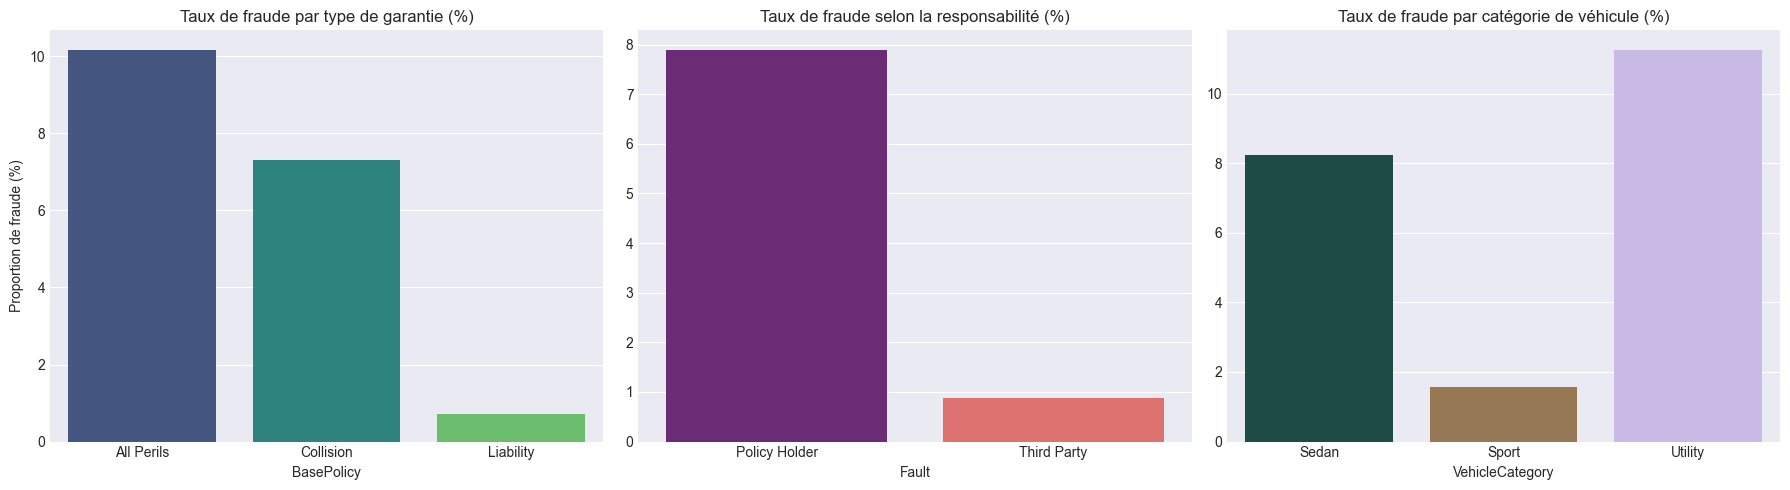

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Fraude selon la garantie déclenchée (BasePolicy)
policy_fraud = df.groupby('BasePolicy')['FraudFound_P'].mean() * 100
sns.barplot(x=policy_fraud.index, y=policy_fraud.values, ax=axes[0], palette='viridis')
axes[0].set_title('Taux de fraude par type de garantie (%)')
axes[0].set_ylabel('Proportion de fraude (%)')

# Fraude selon la responsabilité (Fault)
fault_fraud = df.groupby('Fault')['FraudFound_P'].mean() * 100
sns.barplot(x=fault_fraud.index, y=fault_fraud.values, ax=axes[1], palette='magma')
axes[1].set_title('Taux de fraude selon la responsabilité (%)')
axes[1].set_ylabel('')

# Fraude selon la catégorie du véhicule (VehicleCategory)
veh_fraud = df.groupby('VehicleCategory')['FraudFound_P'].mean() * 100
sns.barplot(x=veh_fraud.index, y=veh_fraud.values, ax=axes[2], palette='cubehelix')
axes[2].set_title('Taux de fraude par catégorie de véhicule (%)')
axes[2].set_ylabel('')

plt.tight_layout()
plt.show() 

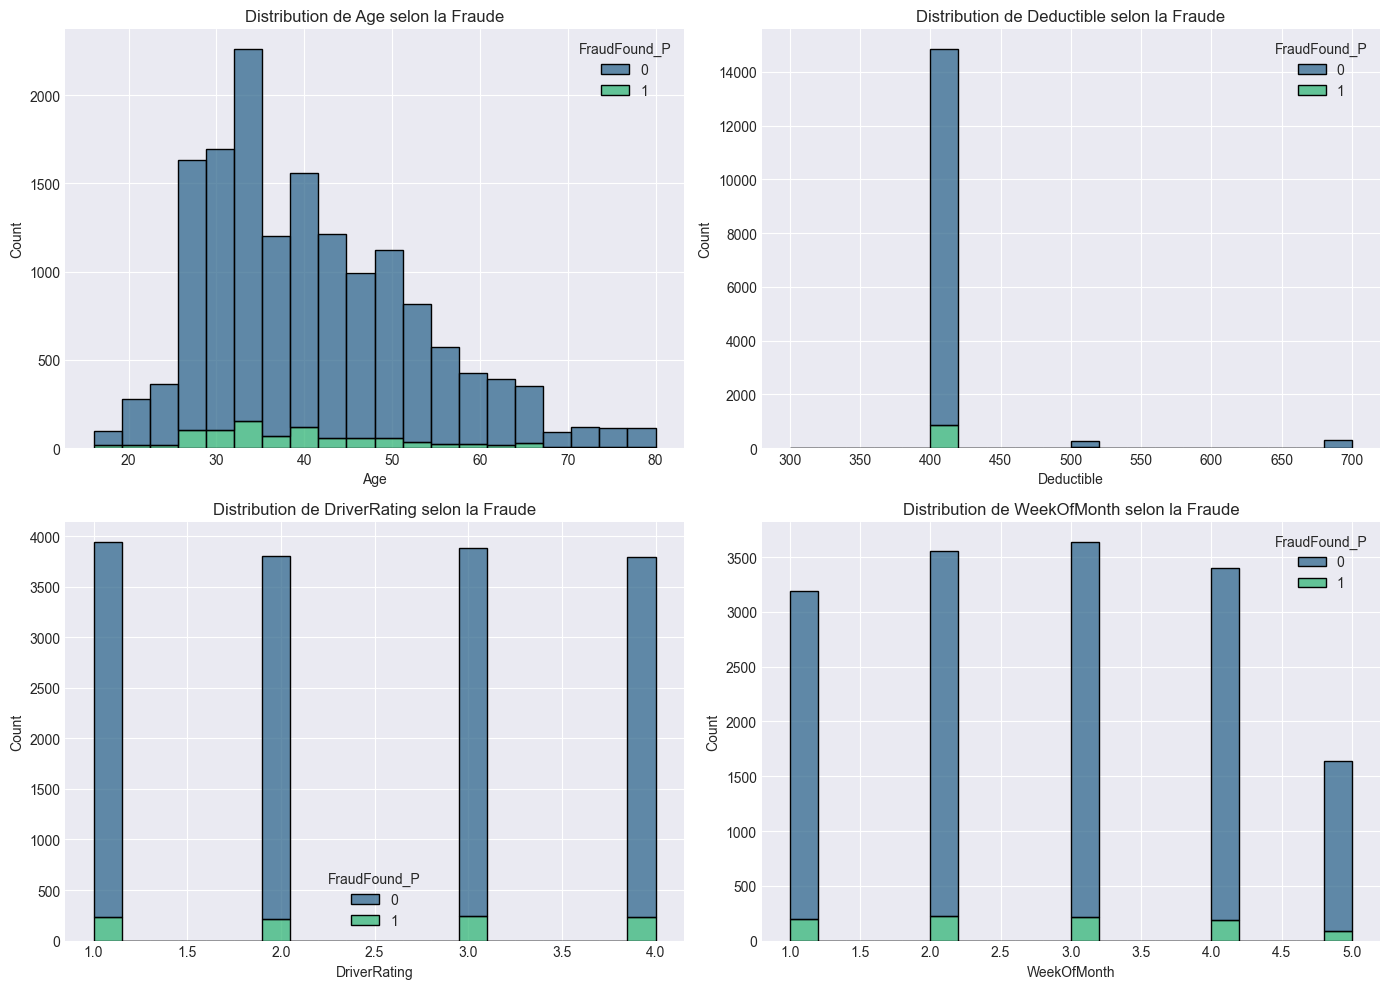

In [28]:
# Sélection de quelques variables numériques pertinentes pour ne pas surcharger
cols_to_plot = ['Age', 'Deductible', 'DriverRating', 'WeekOfMonth']

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(cols_to_plot):
    sns.histplot(data=df, x=col, hue='FraudFound_P', multiple="stack", bins=20, ax=axes[i], palette='viridis')
    axes[i].set_title(f'Distribution de {col} selon la Fraude')

plt.tight_layout()
plt.show() 

In [29]:
num_cols = df.select_dtypes(include = 'number').columns.tolist()
num_cols.remove('Year')

datetime_cols = ['Month', 'DayOfWeek', 'DayOfWeekClaimed', 'MonthClaimed','Year']
temp = df.select_dtypes(exclude = 'number').columns.tolist()

cat_cols = [col for col in temp if col not in datetime_cols]
num_cols 

['WeekOfMonth',
 'WeekOfMonthClaimed',
 'Age',
 'FraudFound_P',
 'PolicyNumber',
 'RepNumber',
 'Deductible',
 'DriverRating']

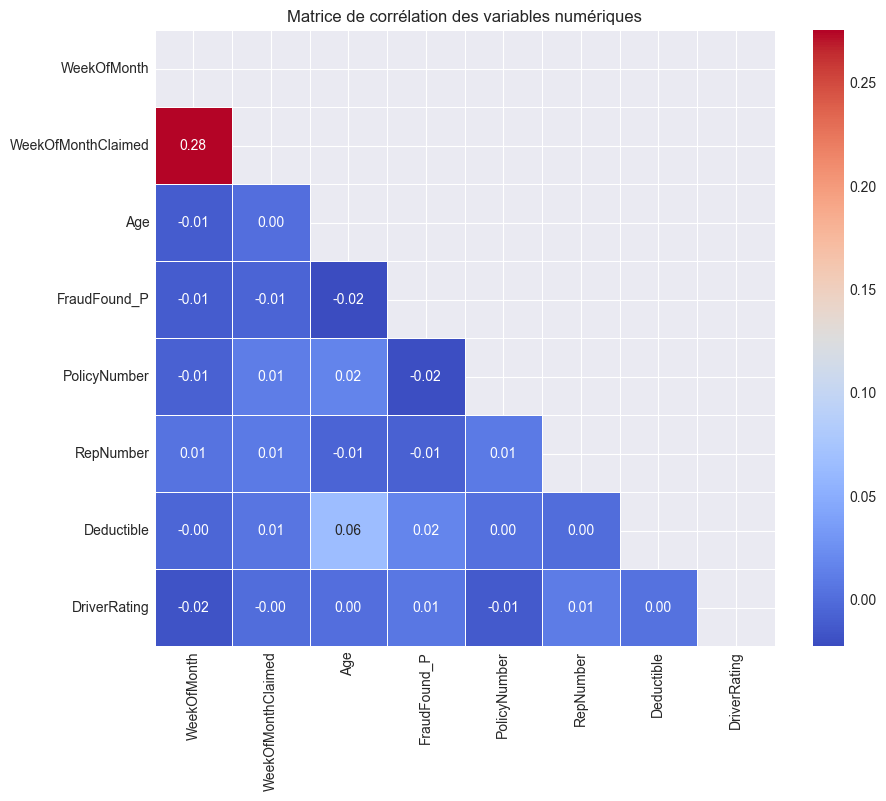

In [30]:
plt.figure(figsize=(10, 8))
# On utilise num_cols défini dans la cellule précédente
corr = df[num_cols].corr()

# Masque pour la partie supérieure de la matrice
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(corr, mask=mask, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Matrice de corrélation des variables numériques')
plt.show() 

In [31]:
df.rename(columns = {'FraudFound_P':'Fraud'},inplace = True)


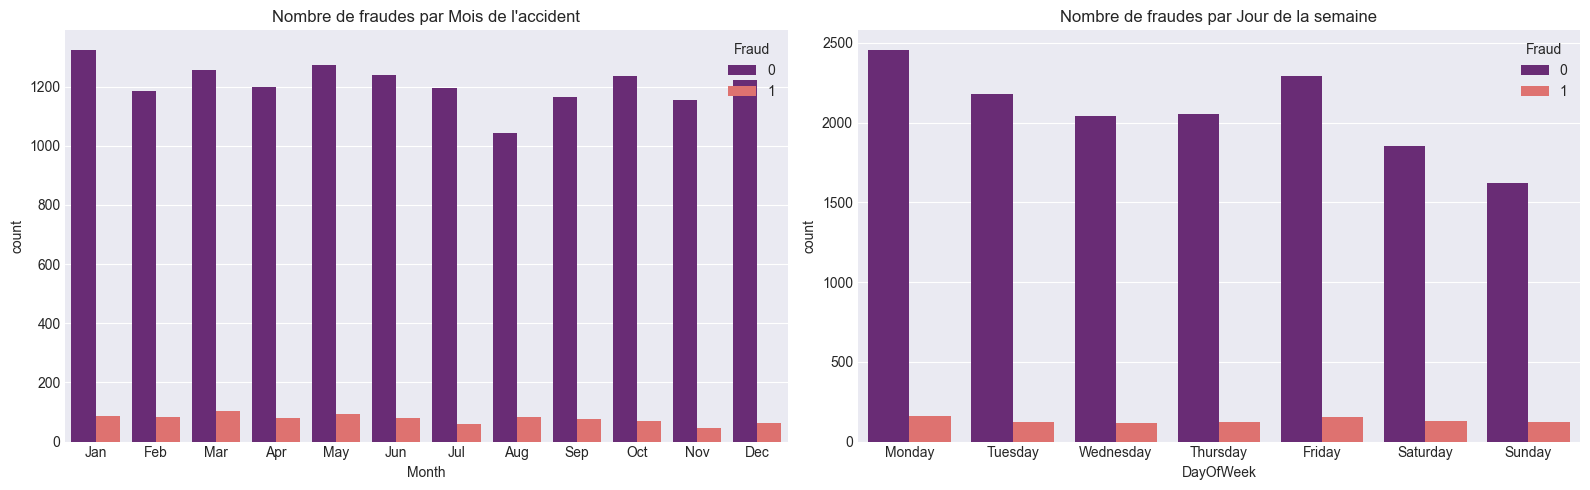

In [32]:
# Ordonner les mois logiquement
months_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

fig, ax = plt.subplots(1, 2, figsize=(16, 5))

# Fraude par mois de l'accident
sns.countplot(data=df, x='Month', hue='Fraud', order=months_order, palette='magma', ax=ax[0])
ax[0].set_title("Nombre de fraudes par Mois de l\'accident")

# Fraude par jour de la semaine
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
sns.countplot(data=df, x='DayOfWeek', hue='Fraud', order=days_order, palette='magma', ax=ax[1])
ax[1].set_title('Nombre de fraudes par Jour de la semaine')

plt.tight_layout()
plt.show() 

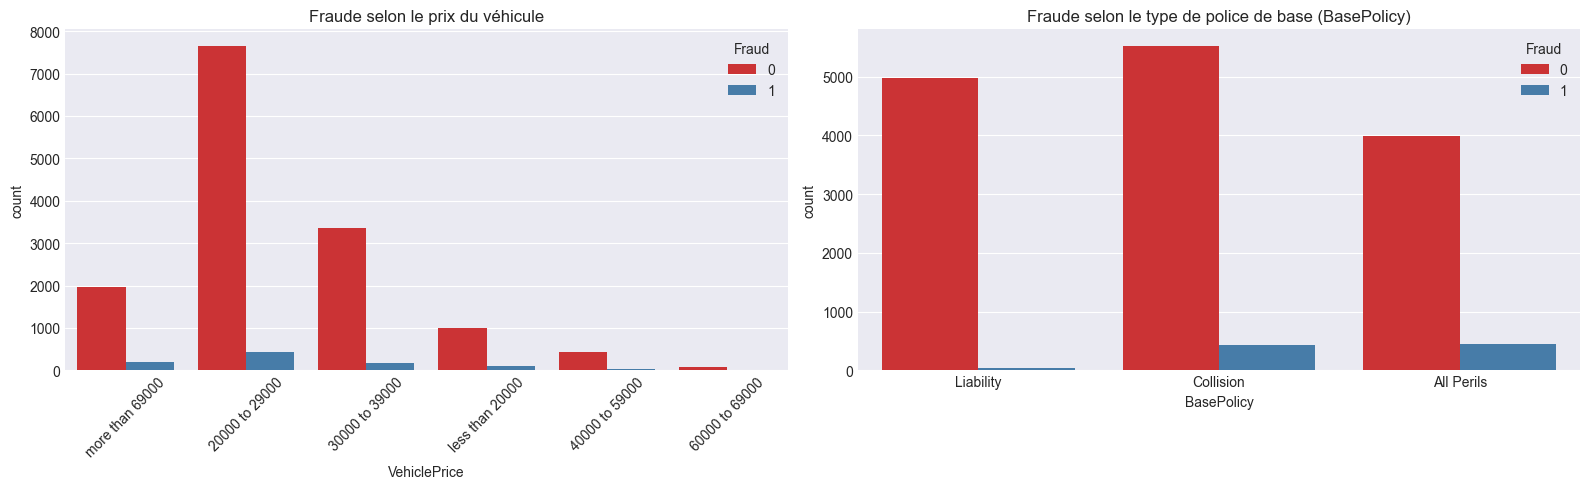

In [33]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))

sns.countplot(data=df, x='VehiclePrice', hue='Fraud', palette='Set1', ax=ax[0])
ax[0].set_title('Fraude selon le prix du véhicule')
ax[0].tick_params(axis='x', rotation=45)

sns.countplot(data=df, x='BasePolicy', hue='Fraud', palette='Set1', ax=ax[1])
ax[1].set_title('Fraude selon le type de police de base (BasePolicy)')

plt.tight_layout()
plt.show() 

## Separation de la base de donnees

In [34]:
from sklearn.model_selection import train_test_split

X = df.drop(['Fraud'],axis = 1)
y = df['Fraud']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42) 

In [ ]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

trf = ColumnTransformer([
    ('ohe',OneHotEncoder(handle_unknown='ignore',sparse_output=False),cat_cols)
])

X_train_trf = trf.fit_transform(X_train)
X_test_trf = trf.transform(X_test)

In [ ]:
#pip install imblearn


   ---------------------------------------- 0/3 [sklearn-compat]
   ---------------------------------------- 0/3 [sklearn-compat]
   ---------------------------------------- 0/3 [sklearn-compat]
   ---------------------------------------- 0/3 [sklearn-compat]
   ---------------------------------------- 0/3 [sklearn-compat]
   ---------------------------------------- 0/3 [sklearn-compat]
   ------------- -------------------------- 1/3 [imbalanced-learn]
   ------------- -------------------------- 1/3 [imbalanced-learn]
   ------------- -------------------------- 1/3 [imbalanced-learn]
   ------------- -------------------------- 1/3 [imbalanced-learn]
   ------------- -------------------------- 1/3 [imbalanced-learn]
   ------------- -------------------------- 1/3 [imbalanced-learn]
   ------------- -------------------------- 1/3 [imbalanced-learn]
   ------------- -------------------------- 1/3 [imbalanced-learn]
   ------------- -------------------------- 1/3 [imbalanced-learn]
   ---


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [38]:
from imblearn.over_sampling import SMOTE

smote = SMOTE()

X_train_smote,y_train_smote = smote.fit_resample(X_train_trf,y_train) 

In [39]:
y_train.value_counts()


Fraud
0    9716
1     614
Name: count, dtype: int64

In [40]:
y_train_smote.value_counts() 


Fraud
0    9716
1    9716
Name: count, dtype: int64

In [41]:
X_train_smote.shape


(19432, 97)

In [ ]:
#pip install xgboost

   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.5/101.7 MB 5.6 MB/s eta 0:00:19
    --------------------------------------- 1.6/101.7 MB 4.2 MB/s eta 0:00:24
   - -------------------------------------- 2.6/101.7 MB 4.3 MB/s eta 0:00:23
   - -------------------------------------- 3.4/101.7 MB 4.3 MB/s eta 0:00:23
   - -------------------------------------- 4.7/101.7 MB 4.8 MB/s eta 0:00:21
   -- ------------------------------------- 6.0/101.7 MB 4.9 MB/s eta 0:00:20
   -- ------------------------------------- 7.1/101.7 MB 5.0 MB/s eta 0:00:20
   --- ------------------------------------ 8.4/101.7 MB 5.1 MB/s eta 0:00:19
   --- ------------------------------------ 9.4/101.7 MB 5.1 MB/s eta 0:00:19
   ---- ----------------------------------- 10.5/101.7 MB 5.1 MB/s eta 0:00:18
   ---- ----------------------------------- 11.5/101.7 MB 5.1 MB/s eta 0:00:18
   ----- ---------------------------------- 13.1/101.7 MB 5.2 MB/s et


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
# pip install catboost 

   ---------------------------------------- 0.0/100.2 MB ? eta -:--:--
   ---------------------------------------- 1.0/100.2 MB 6.3 MB/s eta 0:00:16
    --------------------------------------- 2.4/100.2 MB 6.1 MB/s eta 0:00:17
   - -------------------------------------- 3.7/100.2 MB 6.1 MB/s eta 0:00:16
   - -------------------------------------- 5.0/100.2 MB 6.2 MB/s eta 0:00:16
   -- ------------------------------------- 6.3/100.2 MB 6.0 MB/s eta 0:00:16
   -- ------------------------------------- 7.3/100.2 MB 6.0 MB/s eta 0:00:16
   --- ------------------------------------ 8.7/100.2 MB 5.9 MB/s eta 0:00:16
   --- ------------------------------------ 10.0/100.2 MB 5.9 MB/s eta 0:00:16
   ---- ----------------------------------- 11.5/100.2 MB 6.0 MB/s eta 0:00:15
   ----- ---------------------------------- 12.8/100.2 MB 6.1 MB/s eta 0:00:15
   ----- ---------------------------------- 14.2/100.2 MB 6.1 MB/s eta 0:00:15
   ------ --------------------------------- 15.5/100.2 MB 6.1 MB/s 


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
#pip install lightgbm

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   -------------------------------------- - 1.3/1.4 MB 7.4 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 5.0 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [46]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
import lightgbm as lgb

algos = {
    'LogisticRegression':LogisticRegression(max_iter=1000),
    'RandomForestClassifier':RandomForestClassifier(),
    'GradientBoostingClassifier':GradientBoostingClassifier(),
    'ExtraTreesClassifier':ExtraTreesClassifier(),
    'KNeighborsClassifier':KNeighborsClassifier(),
    'SVC':SVC(),
    'XGBClassifier':XGBClassifier(),
    'Adaboost':AdaBoostClassifier()
    
} 

In [47]:
from sklearn.metrics import accuracy_score,precision_score,roc_auc_score,classification_report

for name,algo in algos.items():
    model = algo
    model.fit(X_train_smote,y_train_smote)
    y_pred = model.predict(X_test_trf)
    print(name)
    print(accuracy_score(y_test,y_pred))
    print(precision_score(y_test,y_pred))
    print('\n') 

LogisticRegression
0.6573000589506779
0.13336739908022482


RandomForestClassifier
0.9210060915700531
0.12195121951219512


GradientBoostingClassifier
0.891530752603655
0.20147420147420148


ExtraTreesClassifier
0.9188445667125172
0.14864864864864866


KNeighborsClassifier
0.7221458046767538
0.11390635918937805


SVC
0.859107879740617
0.1588628762541806


XGBClassifier
0.9325997248968363
0.24242424242424243


Adaboost
0.7398310080565926
0.13981547196593327




In [48]:
lgb_clf = lgb.LGBMClassifier()
lgb_clf.fit(X_train_smote,y_train_smote)
y_pred2 = lgb_clf.predict(X_test_trf)
print(accuracy_score(y_test,y_pred2))
print(precision_score(y_test,y_pred2))
y_prob_lgb = lgb_clf.predict_proba(X_test_trf)[:, 1]
roc_auc_lgb = roc_auc_score(y_test, y_prob_lgb)
print(roc_auc_lgb)
print('\n')
print(classification_report(y_test,y_pred2)) 

[LightGBM] [Info] Number of positive: 9716, number of negative: 9716
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.014268 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 11779
[LightGBM] [Info] Number of data points in the train set: 19432, number of used features: 87
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
0.9355472587934761
0.3389830508474576
0.8004983006323543


              precision    recall  f1-score   support

           0       0.94      0.99      0.97      4780
           1       0.34      0.06      0.11       309

    accuracy                           0.94      5089
   macro avg       0.64      0.53      0.54      5089
weighted avg       0.91      0.94      0.91      5089



In [49]:
xgb_clf = XGBClassifier()
xgb_clf.fit(X_train_smote,y_train_smote)
y_pred3 = xgb_clf.predict(X_test_trf)
print(accuracy_score(y_test,y_pred3))
print(precision_score(y_test,y_pred3))
y_prob_xgb = xgb_clf.predict_proba(X_test_trf)[:, 1]
roc_auc_xgb = roc_auc_score(y_test, y_prob_xgb)
print(roc_auc_xgb) 

0.9325997248968363
0.24242424242424243
0.7969242122652369


In [50]:
## Voting Classifier
np.random.seed(42)

from sklearn.ensemble import VotingClassifier
from sklearn.metrics import classification_report

voting_clf = VotingClassifier([
    ('lgb',lgb_clf),
    ('xgb',xgb_clf),
])

voting_clf.fit(X_train_smote,y_train_smote)
y_pred4 = voting_clf.predict(X_test_trf)
print(accuracy_score(y_test,y_pred4))
print(precision_score(y_test,y_pred4))
print(classification_report(y_test,y_pred4)) 

[LightGBM] [Info] Number of positive: 9716, number of negative: 9716
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.015542 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 11779
[LightGBM] [Info] Number of data points in the train set: 19432, number of used features: 87
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
0.9363332678325801
0.3170731707317073
              precision    recall  f1-score   support

           0       0.94      0.99      0.97      4780
           1       0.32      0.04      0.07       309

    accuracy                           0.94      5089
   macro avg       0.63      0.52      0.52      5089
weighted avg       0.90      0.94      0.91      5089



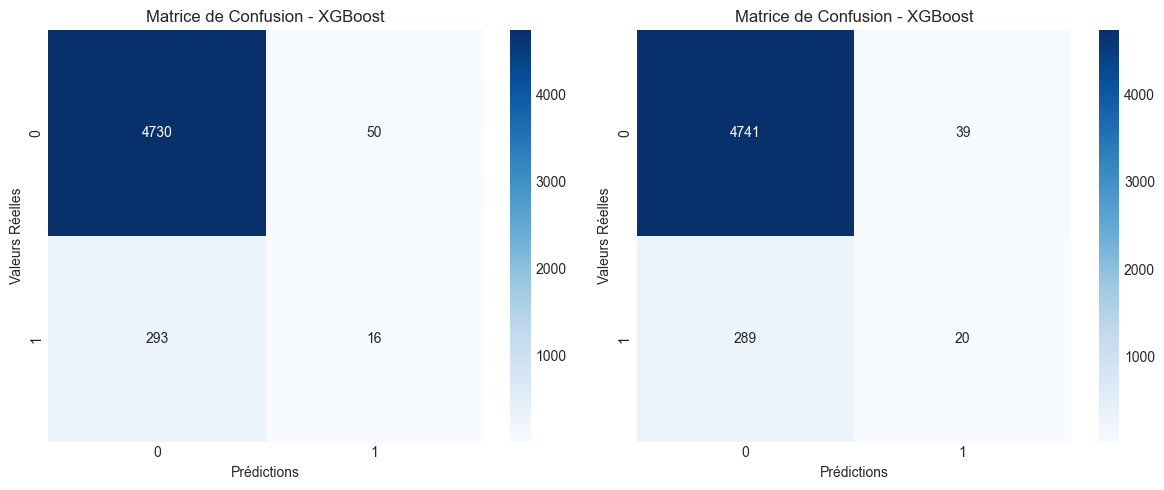

In [62]:
from sklearn.metrics import confusion_matrix
fig, axes = plt.subplots(1,2, figsize =(12,5))

# Matrice pour XGBoost
cm_xgb = confusion_matrix(y_test, y_pred3)
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Matrice de Confusion - XGBoost')
axes[0].set_xlabel('Prédictions')
axes[0].set_ylabel('Valeurs Réelles') 

# Matrice pour LightGBM
cm_lgb = confusion_matrix(y_test, y_pred2)
sns.heatmap(cm_lgb, annot=True, fmt='d', cmap='Blues', ax=axes[1])
axes[1].set_title('Matrice de Confusion - XGBoost')
axes[1].set_xlabel('Prédictions')
axes[1].set_ylabel('Valeurs Réelles') 

plt.tight_layout()
plt.show() 